In [41]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor # 예측관련(regression)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위
from sklearn.neighbors import KNeighborsClassifier # 분류 관련(classifier)
from sklearn.preprocessing import StandardScaler # 정규화클래스
import numpy as np

In [42]:
df = pd.read_csv('data/QuizData.csv', sep=',')
df

,total,reception
0,118,62
1,253,148
2,320,201
3,94,80
4,155,92
5,188,131
6,201,147
7,338,187
8,186,124
9,183,152


In [ ]:
# 자료형태가 같은 지 확인해야 함
label = df.iloc[:,-1:]
label
data = df.iloc[:,:1]
data

,total
0,118
1,253
2,320
3,94
4,155
5,188
6,201
7,338
8,186
9,183


In [44]:
train_data, test_data, train_label, test_label = \
train_test_split(data,label)

In [45]:
lr = LinearRegression()
lr.fit(train_data,train_label)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.58]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['total']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[9.04]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [46]:
predict05 = lr.predict(test_data)
print("예측치 :", predict05)

예측치 : [[ 63.55424584]
 [118.06473702]
 [ 58.9150551 ]
 [236.36410088]
 [116.90493934]]


In [47]:
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("정확도1",score)
print("정확도2",score2)

정확도1 0.8610224484848248
정확도2 0.8403755458020636


In [48]:
visitors = input('참석인원을 입력하세요')
visitors = float(visitors)
reception = lr.predict([[visitors]])
print("식사인원",reception)

식사인원 [[183.01340738]]


c:\python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [49]:
print('기울기', lr.coef_)
print('절편', lr.intercept_)

기울기 [[0.57989884]]
절편 [9.04375465]


Text(0, 0.5, '식사인원')

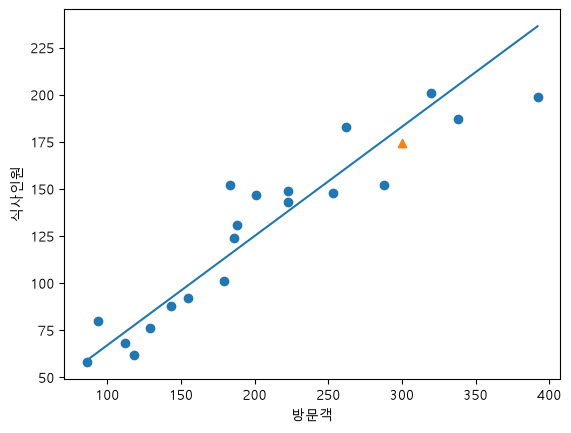

In [50]:
plt.scatter(data,label)
plt.scatter(300,174.47919619, marker='^')
plt.plot([86,392],[86*lr.coef_[0] + lr.intercept_, 392*lr.coef_[0] + lr.intercept_])
plt.xlabel("방문객")
plt.ylabel("식사인원")